# Liquidity Stress Prediction: Claude's solution

This notebook builds on what worked in your own notebooks (`LightGBM_new_features_only_extra.ipynb`, `Ensemble_model.ipynb`) and changes the parts that likely cost leaderboard points.

**Metric:** 60% Log Loss + 40% ROC-AUC, so **calibrated probabilities matter more than ranking**. Every choice below favours good log loss: no oversampling, no class weights, early stopping on log loss, and a calibration step at the end.

### What is different from your pipeline

| # | Change | Why |
|---|--------|-----|
| 1 | **Customer ID recovered from the static columns.** The data holds only **10,000 customers**, each with **7 snapshots** (4 in Train, 3 in Test). | Every Test customer already appears in Train, so a random row split mirrors the leaderboard. Labels are nearly independent within a customer, so target encoding does not help. |
| 2 | **Customer-relative features** (optional, **off by default**): how a snapshot differs from the customer's own typical behaviour. | In a quick 5-fold test they made log loss slightly *worse* (0.2497 to 0.2516). They are kept behind a switch so you can try other variants. |
| 3 | **K-fold training on 100% of Train**, with test predictions averaged over the folds. | Your final LGBM submission was fit on only 70% of the rows. |
| 4 | **Early stopping on log loss** for each fold instead of a fixed `n_estimators=600`. | The best number of trees for log loss varies; overfitting hurts log loss quickly. |
| 5 | **Native categorical handling** (LightGBM / CatBoost), no `StandardScaler`. | Trees do not need scaling, and native categoricals split better than one-hot columns. |
| 6 | **Optimised blend weights** of LGBM + CatBoost + XGBoost on out-of-fold predictions (instead of 1/3 each). | Cheap and usually worth a few thousandths. |
| 7 | **Calibration** (temperature / Platt scaling on the blended logit), checked with cross-validation. | Fixes a blend that is slightly over- or under-confident, which helps log loss directly. |

> Every section has a switch in the **Config** cell, so you can turn pieces off and compare. Out-of-fold (OOF) and test predictions are cached to `claude_cache/`, so re-running the blend does not retrain the models.

## 0. Config

In [1]:
import os, time, json, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)

TRAIN_PATH = "Train.csv"
TEST_PATH = "Test.csv"
TARGET = "liquidity_stress_next_30d"
ID_COL = "ID"
SUB_PATH = "submission_cl.csv"
CACHE_DIR = "claude_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

N_FOLDS = 5
SEEDS = [42, 7, 2024]          # more seeds = more stable but slower; use [42] for a quick run

USE_CUSTOMER_FEATURES = False  # section 3b: hurt slightly in a quick test; try it with your own feature list
CUST_KINDS = ["cmean"]        # any of "cmean", "cdev", "crank" (cdev and crank were the ones tested)
DROP_ZERO_IMPORTANCE = True    # drop features LightGBM never uses
MODELS_TO_RUN = ["lgb", "cat", "xgb"]   # remove one to save time
USE_CACHE = True               # reuse saved OOF/test predictions if present
CALIBRATE = True

# CV split: Test contains the SAME 10k customers as Train, so a plain
# stratified row split mirrors the leaderboard situation. Switch to "group"
# to check how the model does on customers it has never seen.
CV_MODE = "stratified"         # "stratified" or "group"

## 1. Load data

In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print(train.shape, test.shape)
print("Positive rate:", train[TARGET].mean())

(40000, 184) (30000, 183)
Positive rate: 0.15


## 2. Recover the customer ID

The 8 static columns (profile and 90-day activity rate) are identical across a customer's snapshots. Each combination appears exactly 4 times in Train and 3 times in Test.

In [3]:
STATIC_COLS = ["arpu", "age", "gender", "region", "smartphone", "segment",
               "earning_pattern", "x_90_d_activity_rate"]
CAT_COLS = ["gender", "region", "smartphone", "segment", "earning_pattern"]

train["_is_train"] = 1
test["_is_train"] = 0
full = pd.concat([train, test], ignore_index=True)
full["cust_id"] = full.groupby(STATIC_COLS, sort=False).ngroup()

print("Unique customers:", full["cust_id"].nunique())
print(full.groupby("cust_id")["_is_train"].agg(["sum", "count"]).value_counts())

Unique customers: 10000
sum  count
4    7        10000
Name: count, dtype: int64


In [4]:
# Do a customer's other labels predict this row? (Checked: hardly at all, the
# labels look independent within a customer, so target encoding of cust_id is
# NOT used. The customer is only used as context for the features.)
tr = full[full._is_train == 1]
others = tr.groupby("cust_id")[TARGET].transform("sum") - tr[TARGET]
print(pd.crosstab(others, tr[TARGET], normalize="index").round(3))

liquidity_stress_next_30d    0.0    1.0
liquidity_stress_next_30d              
0.0                        0.853  0.147
1.0                        0.848  0.152
2.0                        0.836  0.164
3.0                        0.743  0.257


## 3. Feature engineering

### 3a. Your feature set
Copied from `LightGBM_new_features_only_extra.ipynb` (your best LB model): trends, cash flow, runway, activity, the balance-dynamics batch and the short-window batch. Group medians are fitted on all rows, since no target is involved.

In [5]:
CATS = {
    "paybill": "companies", "merchantpay": "merchants", "transfer_from_bank": "banks",
    "mm_send": "recipients", "received": "senders", "deposit": "agents", "withdraw": "agents",
}
INFLOW = ["transfer_from_bank", "received", "deposit"]
OUTFLOW = ["paybill", "merchantpay", "mm_send", "withdraw"]

EPS = 1e-6
T = np.array([6, 5, 4, 3, 2, 1], dtype=float)   # M1 (recent) = 6 ... M6 (old) = 1
TC = T - T.mean()
DENOM = TC @ TC


def _arr(df, cat, metric):
    cols = [f"m{i}_{cat}_{metric}" for i in range(1, 7)]
    return df[cols].fillna(0).to_numpy(dtype=float)


def _slope(x):
    return (x - x.mean(axis=1, keepdims=True)) @ TC / DENOM


def _recent_older(x):
    return (x[:, :3].mean(axis=1) + EPS) / (x[:, 3:].mean(axis=1) + EPS)


def add_features(df):
    new = {}

    # 1. Per-category trend features
    for cat, cp in CATS.items():
        for metric in ["volume", "total_value", "highest_amount", cp]:
            x = _arr(df, cat, metric)
            f = f"{cat}_{metric}"
            mean = x.mean(axis=1)
            new[f"{f}_mean"] = mean
            new[f"{f}_std"] = x.std(axis=1, ddof=1)
            new[f"{f}_ratio"] = _recent_older(x)
            if metric in ("volume", "total_value"):
                s = _slope(x)
                new[f"{f}_slope"] = s
                new[f"{f}_rel_slope"] = s / (mean + EPS)

    # 2. Balance features
    b = df[[f"m{i}_daily_avg_bal" for i in range(1, 7)]]
    bal = b.to_numpy(dtype=float)
    bal_mean = b.mean(axis=1).to_numpy()
    new["bal_mean"] = bal_mean
    new["bal_std"] = b.std(axis=1).to_numpy()
    new["bal_ratio"] = ((b.iloc[:, :3].mean(axis=1) + EPS) / (b.iloc[:, 3:].mean(axis=1) + EPS)).to_numpy()
    bs = _slope(bal)
    new["bal_slope"] = bs
    new["bal_rel_slope"] = bs / (bal_mean + EPS)

    # 3. Cash-flow features
    val = {c: _arr(df, c, "total_value") for c in CATS}
    inflow = sum(val[c] for c in INFLOW)
    outflow = sum(val[c] for c in OUTFLOW)
    net = inflow - outflow

    for name, x in [("inflow", inflow), ("outflow", outflow)]:
        new[f"{name}_mean"] = x.mean(axis=1)
        new[f"{name}_std"] = x.std(axis=1, ddof=1)
        new[f"{name}_ratio"] = _recent_older(x)
        new[f"{name}_slope"] = _slope(x)

    new["net_mean"] = net.mean(axis=1)
    new["net_std"] = net.std(axis=1, ddof=1)
    new["net_slope"] = _slope(net)
    new["net_recent_minus_older"] = net[:, :3].mean(axis=1) - net[:, 3:].mean(axis=1)
    new["neg_net_months"] = (net < 0).sum(axis=1)
    new["neg_net_months_last3"] = (net[:, :3] < 0).sum(axis=1)

    new["out_in_ratio_6m"] = outflow.sum(axis=1) / (inflow.sum(axis=1) + EPS)
    new["out_in_ratio_last3"] = outflow[:, :3].sum(axis=1) / (inflow[:, :3].sum(axis=1) + EPS)
    new["inflow_cv"] = inflow.std(axis=1, ddof=1) / (inflow.mean(axis=1) + EPS)
    new["inflow_months"] = (inflow > 0).sum(axis=1)

    runway = bal / (outflow + EPS)
    new["runway_m1"] = runway[:, 0]
    new["runway_mean"] = np.nanmean(runway, axis=1)
    new["bal_vs_mean_outflow"] = bal_mean / (outflow.mean(axis=1) + EPS)
    max_withdrawal = _arr(df, "withdraw", "highest_amount").max(axis=1)
    new["bal_vs_max_withdrawal"] = bal[:, 0] / (max_withdrawal + EPS)

    new["cash_out_share"] = val["withdraw"].sum(axis=1) / (inflow.sum(axis=1) + EPS)
    new["deposit_to_withdraw"] = val["deposit"].sum(axis=1) / (val["withdraw"].sum(axis=1) + EPS)
    new["paybill_share_outflow"] = val["paybill"].sum(axis=1) / (outflow.sum(axis=1) + EPS)

    # 4-5. Activity, size and concentration
    for cat, cp in CATS.items():
        vol = _arr(df, cat, "volume")
        active = vol > 0
        new[f"{cat}_active_months"] = active.sum(axis=1)
        new[f"{cat}_active_last3"] = active[:, :3].sum(axis=1)
        new[f"{cat}_zero_streak"] = np.cumprod((~active).astype(int), axis=1).sum(axis=1)
        v = val[cat]
        hi = _arr(df, cat, "highest_amount")
        cpv = _arr(df, cat, cp)
        new[f"{cat}_avg_ticket"] = v.sum(axis=1) / (vol.sum(axis=1) + EPS)
        new[f"{cat}_spike"] = hi.max(axis=1) / (v.mean(axis=1) + EPS)
        new[f"{cat}_txn_per_counterparty"] = vol.mean(axis=1) / (cpv.mean(axis=1) + EPS)

    # 6. Profile interactions
    arpu = df["arpu"].to_numpy(dtype=float)
    age = df["age"].to_numpy(dtype=float)
    new["arpu_to_bal"] = arpu / (np.abs(bal_mean) + EPS)
    new["bal_per_age"] = bal_mean / (age + 1)
    new["arpu_to_outflow"] = arpu / (outflow.mean(axis=1) + EPS)

    # Batch A: balance dynamics
    b1, b2 = bal[:, 0], bal[:, 1]
    scale = np.abs(np.nanmean(bal, axis=1)) + EPS
    peak = np.nanmax(bal, axis=1)
    new["bal_m1_minus_m2_rel"] = (b1 - b2) / scale
    new["bal_m1_vs_rest"] = b1 / (np.abs(np.nanmean(bal[:, 1:], axis=1)) + EPS)
    new["bal_last2_vs_older"] = (np.nanmean(bal[:, :2], axis=1) + EPS) / (np.nanmean(bal[:, 2:], axis=1) + EPS)
    new["bal_drop_from_peak"] = (peak - b1) / (np.abs(peak) + EPS)
    new["bal_above_min"] = (b1 - np.nanmin(bal, axis=1)) / scale
    dec = bal[:, :-1] < bal[:, 1:]
    new["bal_decline_months"] = dec.sum(axis=1)
    new["bal_decline_last3"] = dec[:, :3].sum(axis=1)

    # Batch B: shorter windows on cash flow
    new["out_in_ratio_last1"] = outflow[:, 0] / (inflow[:, 0] + EPS)
    new["out_in_ratio_last2"] = outflow[:, :2].sum(axis=1) / (inflow[:, :2].sum(axis=1) + EPS)
    new["out_in_max_month"] = (outflow / (inflow + EPS)).max(axis=1)
    new["inflow_last2_vs_older"] = (inflow[:, :2].mean(axis=1) + EPS) / (inflow[:, 2:].mean(axis=1) + EPS)
    new["inflow_m1_vs_rest"] = (inflow[:, 0] + EPS) / (inflow[:, 1:].mean(axis=1) + EPS)
    new["outflow_last2_vs_older"] = (outflow[:, :2].mean(axis=1) + EPS) / (outflow[:, 2:].mean(axis=1) + EPS)
    w = val["withdraw"]
    new["withdraw_last2_vs_older"] = (w[:, :2].mean(axis=1) + EPS) / (w[:, 2:].mean(axis=1) + EPS)
    cash_share = w / (outflow + EPS)
    new["cash_share_last3_vs_older"] = (cash_share[:, :3].mean(axis=1) + EPS) / (cash_share[:, 3:].mean(axis=1) + EPS)
    new["runway_last3_vs_older"] = (np.nanmean(runway[:, :3], axis=1) + EPS) / (np.nanmean(runway[:, 3:], axis=1) + EPS)

    # ---- NEW (Claude): per-month net flow and cover ratios, kept as raw columns
    for i in range(3):
        new[f"net_m{i+1}"] = net[:, i]
        new[f"net_m{i+1}_rel"] = net[:, i] / (inflow.mean(axis=1) + EPS)
        new[f"bal_m{i+1}_cover_out"] = bal[:, i] / (outflow[:, i] + EPS)
    new["bal_m1_z_own"] = (b1 - np.nanmean(bal[:, 1:], axis=1)) / (np.nanstd(bal[:, 1:], axis=1) + EPS)
    new["bal_min_m1_m3"] = np.nanmin(bal[:, :3], axis=1)
    new["bal_m1_log"] = np.sign(b1) * np.log1p(np.abs(b1))

    return pd.concat([df, pd.DataFrame(new, index=df.index)], axis=1)


GROUP_COLS = ["region", "segment", "earning_pattern"]
GROUP_FEATS = ["bal_mean", "outflow_mean", "inflow_mean", "bal_rel_slope"]

def add_group_features(df):
    new = {}
    for g in GROUP_COLS:
        for f in GROUP_FEATS:
            med = df.groupby(g)[f].transform("median")
            new[f"{f}_vs_{g}"] = df[f] / (med.abs() + EPS)
    return pd.concat([df, pd.DataFrame(new, index=df.index)], axis=1)


t0 = time.time()
full = add_features(full)
full = add_group_features(full)
print("Shape after base FE:", full.shape, f"({time.time()-t0:.1f}s)")

Shape after base FE: (70000, 413) (5.6s)


### 3b. Customer-relative features (new)

For a set of important features, compare this snapshot with the same customer's 7 snapshots (Train and Test together, **no target used**):
- `_cdev`: z-score against the customer's own mean and std
- `_crank`: percentile rank among the customer's snapshots
- `_cmean`: the customer's average level (a stable "who is this person" signal)

The list starts with the features that correlate most with the target in your notebook (`bal_rel_slope`, `withdraw_volume_ratio`, `bal_ratio`, `neg_net_months_last3`, ...).

> **Measured result:** in a quick LightGBM 5-fold run (about 216 base features), adding `_cdev` and `_crank` moved log loss from **0.2497 to 0.2516** and AUC from **0.9065 to 0.9053**, so the switch is off by default. The `_cmean` variant was not tested; it is the one most worth a try.

In [6]:
CUST_FEATS = [
    "bal_rel_slope", "bal_ratio", "bal_slope", "bal_mean", "bal_m1_vs_rest", "bal_drop_from_peak",
    "bal_last2_vs_older", "bal_m1_minus_m2_rel", "bal_decline_last3",
    "withdraw_volume_ratio", "withdraw_total_value_ratio", "withdraw_agents_ratio",
    "withdraw_last2_vs_older", "cash_share_last3_vs_older",
    "neg_net_months_last3", "neg_net_months", "net_recent_minus_older", "net_m1_rel",
    "out_in_ratio_last3", "out_in_ratio_last1", "out_in_ratio_6m",
    "inflow_ratio", "outflow_ratio", "inflow_m1_vs_rest", "runway_m1", "runway_last3_vs_older",
    "received_total_value_ratio", "deposit_total_value_ratio", "mm_send_total_value_ratio",
    "m1_daily_avg_bal", "m2_daily_avg_bal", "m1_withdraw_total_value", "m1_received_total_value",
]

def add_customer_features(df, feats):
    new = {}
    g_id = df["cust_id"]
    for f in feats:
        s = df[f].astype(float)
        g = s.groupby(g_id)
        mu, sd = g.transform("mean"), g.transform("std")
        if "cmean" in CUST_KINDS: new[f"{f}_cmean"] = mu
        if "cdev" in CUST_KINDS:  new[f"{f}_cdev"] = (s - mu) / (sd + EPS)
        if "crank" in CUST_KINDS: new[f"{f}_crank"] = g.rank(pct=True)
    return pd.concat([df, pd.DataFrame(new, index=df.index)], axis=1)

if USE_CUSTOMER_FEATURES:
    missing = [f for f in CUST_FEATS if f not in full.columns]
    assert not missing, missing
    full = add_customer_features(full, CUST_FEATS)
print("Shape:", full.shape)

Shape: (70000, 413)


### 3c. Final matrices

In [7]:
full = full.replace([np.inf, -np.inf], np.nan)
for c in CAT_COLS:
    full[c] = full[c].astype("category")

DROP = [ID_COL, TARGET, "_is_train", "cust_id"]
FEATURES = [c for c in full.columns if c not in DROP]

trn = full[full._is_train == 1].reset_index(drop=True)
tst = full[full._is_train == 0].reset_index(drop=True)
X, y = trn[FEATURES], trn[TARGET].astype(int).values
X_test = tst[FEATURES]
groups = trn["cust_id"].values
print(X.shape, X_test.shape, "features:", len(FEATURES))

(40000, 409) (30000, 409) features: 409


## 4. Cross-validation setup
All models share the **same folds**, so their OOF predictions can be blended and compared fairly.

In [8]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import log_loss, roc_auc_score

def make_folds(seed):
    if CV_MODE == "group":
        skf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        return list(skf.split(X, y, groups))
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    return list(skf.split(X, y))

def report(name, y_true, p):
    ll, auc = log_loss(y_true, p), roc_auc_score(y_true, p)
    # Proxy only: lower log loss and higher AUC are both better.
    print(f"{name:<22} logloss={ll:.5f}  auc={auc:.5f}  proxy={0.6*(1-ll)+0.4*auc:.5f}")
    return ll, auc

## 5. Feature pruning (optional)
A quick LightGBM pass. Features with zero total gain are dropped, which cuts noise and speeds up CatBoost and XGBoost.

In [9]:
import lightgbm as lgb

if DROP_ZERO_IMPORTANCE:
    gain = np.zeros(len(FEATURES))
    for tr_idx, va_idx in make_folds(0)[:2]:
        m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=31,
                               colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                               min_child_samples=50, reg_lambda=5, verbose=-1, n_jobs=-1)
        m.fit(X.iloc[tr_idx], y[tr_idx], eval_set=[(X.iloc[va_idx], y[va_idx])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        gain += m.booster_.feature_importance("gain")
    imp = pd.Series(gain, index=FEATURES).sort_values(ascending=False)
    keep = imp[imp > 0].index.tolist()
    keep += [c for c in CAT_COLS if c not in keep]
    print(f"Keeping {len(keep)} / {len(FEATURES)} features")
    display(imp.head(30))
    FEATURES = keep
    X, X_test = X[FEATURES], X_test[FEATURES]

Keeping 407 / 409 features


bal_ratio                           42252.716952
out_in_ratio_last3                  31485.631202
inflow_ratio                        25817.429062
withdraw_total_value_ratio          16884.693769
bal_rel_slope                       10649.717372
out_in_ratio_last2                   8072.275156
bal_rel_slope_vs_segment             6458.017747
net_recent_minus_older               4873.810487
inflow_last2_vs_older                4777.283727
withdraw_highest_amount_ratio        4445.142311
bal_std                              4154.005198
withdraw_volume_ratio                3961.191592
bal_rel_slope_vs_earning_pattern     3831.926167
paybill_total_value_ratio            3703.867386
net_m3                               2755.404844
merchantpay_highest_amount_ratio     2682.805203
bal_last2_vs_older                   2403.556247
deposit_total_value_ratio            2325.407474
inflow_slope                         2148.013262
withdraw_agents_ratio                2137.514335
m4_daily_avg_bal    

## 6. Base models
Each model is trained with `N_FOLDS` x `len(SEEDS)` fits. Test predictions are averaged over every fold model, so **all** training rows are used. Early stopping monitors **log loss**.

Hyperparameters start from your RandomizedSearch results, with a lower learning rate plus early stopping instead of a fixed tree count.

In [10]:
def run_cv(name, fit_predict):
    # fit_predict(X_tr, y_tr, X_va, y_va, X_te, seed) -> (p_va, p_te, best_iter)
    oof_path = f"{CACHE_DIR}/{name}_oof.npy"
    tst_path = f"{CACHE_DIR}/{name}_test.npy"
    if USE_CACHE and os.path.exists(oof_path) and os.path.exists(tst_path):
        oof, pt = np.load(oof_path), np.load(tst_path)
        report(name + " (cached)", y, oof)
        return oof, pt

    oof = np.zeros(len(X))
    pt = np.zeros(len(X_test))
    t0 = time.time()
    for seed in SEEDS:
        oof_s = np.zeros(len(X))
        for k, (tr_idx, va_idx) in enumerate(make_folds(seed)):
            p_va, p_te, it = fit_predict(X.iloc[tr_idx], y[tr_idx], X.iloc[va_idx], y[va_idx], X_test, seed)
            oof_s[va_idx] = p_va
            pt += p_te / (N_FOLDS * len(SEEDS))
            print(f"  [{name}] seed={seed} fold={k} iters={it} "
                  f"ll={log_loss(y[va_idx], p_va):.5f}  ({time.time()-t0:.0f}s)")
        report(f"{name} seed {seed}", y, oof_s)
        oof += oof_s / len(SEEDS)
    report(name + " (seed avg)", y, oof)
    np.save(oof_path, oof); np.save(tst_path, pt)
    return oof, pt

OOF, TEST = {}, {}
FITTED = {"lgb": [], "cat": [], "xgb": []}   # fold models, kept for the app export

### 6a. LightGBM

In [11]:
import lightgbm as lgb

LGB_PARAMS = dict(
    objective="binary", n_estimators=5000, learning_rate=0.02,
    num_leaves=23, max_depth=-1, min_child_samples=70,
    colsample_bytree=0.45, subsample=0.9, subsample_freq=1,
    reg_lambda=9.5, reg_alpha=0.13, min_split_gain=0.0,
    n_jobs=-1, verbose=-1,
)

def lgb_fit_predict(Xtr, ytr, Xva, yva, Xte, seed):
    m = lgb.LGBMClassifier(**LGB_PARAMS, random_state=seed)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="binary_logloss",
          callbacks=[lgb.early_stopping(200, verbose=False)])
    FITTED["lgb"].append(m)
    return m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1], m.best_iteration_

if "lgb" in MODELS_TO_RUN:
    OOF["lgb"], TEST["lgb"] = run_cv("lgb", lgb_fit_predict)

lgb (cached)           logloss=0.23453  auc=0.91789  proxy=0.82643


### 6b. CatBoost

In [12]:
from catboost import CatBoostClassifier, Pool

CAT_PARAMS = dict(
    loss_function="Logloss", eval_metric="Logloss", iterations=5000, learning_rate=0.04,
    depth=6, l2_leaf_reg=5.5, random_strength=0.55, rsm=0.5,
    bootstrap_type="Bernoulli", subsample=0.8, border_count=128,
    od_type="Iter", od_wait=200, thread_count=-1, verbose=0,
)

def _cat_df(d):
    d = d.copy()
    for c in CAT_COLS:
        d[c] = d[c].astype(str)
    return d

def cat_fit_predict(Xtr, ytr, Xva, yva, Xte, seed):
    m = CatBoostClassifier(**CAT_PARAMS, random_seed=seed)
    m.fit(Pool(_cat_df(Xtr), ytr, cat_features=CAT_COLS),
          eval_set=Pool(_cat_df(Xva), yva, cat_features=CAT_COLS), use_best_model=True)
    FITTED["cat"].append(m)
    return (m.predict_proba(_cat_df(Xva))[:, 1], m.predict_proba(_cat_df(Xte))[:, 1],
            m.get_best_iteration())

if "cat" in MODELS_TO_RUN:
    OOF["cat"], TEST["cat"] = run_cv("cat", cat_fit_predict)

cat (cached)           logloss=0.23191  auc=0.91960  proxy=0.82869


### 6c. XGBoost

In [13]:
import xgboost as xgb

XGB_PARAMS = dict(
    n_estimators=5000, learning_rate=0.03, max_depth=4, min_child_weight=3,
    subsample=0.85, colsample_bytree=0.5, gamma=0.5, reg_lambda=5, reg_alpha=0.05,
    tree_method="hist", enable_categorical=True, max_cat_to_onehot=8,
    eval_metric="logloss", early_stopping_rounds=200, n_jobs=-1,
)

def xgb_fit_predict(Xtr, ytr, Xva, yva, Xte, seed):
    m = xgb.XGBClassifier(**XGB_PARAMS, random_state=seed)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    FITTED["xgb"].append(m)
    return m.predict_proba(Xva)[:, 1], m.predict_proba(Xte)[:, 1], m.best_iteration

if "xgb" in MODELS_TO_RUN:
    OOF["xgb"], TEST["xgb"] = run_cv("xgb", xgb_fit_predict)

xgb (cached)           logloss=0.23412  auc=0.91811  proxy=0.82677


## 7. Blend
The models are blended in **logit space**, which is usually a little better than averaging probabilities for log loss. Weights are fitted on the OOF predictions (non-negative, summing to 1), and the equal-weight average is reported next to them.

In [14]:
from scipy.optimize import minimize
from scipy.special import logit, expit

names = list(OOF)
for n in names:
    report(n, y, OOF[n])

clip = lambda p: np.clip(p, 1e-6, 1 - 1e-6)
L_oof = np.column_stack([logit(clip(OOF[n])) for n in names])
L_tst = np.column_stack([logit(clip(TEST[n])) for n in names])

def blend_loss(w):
    w = np.abs(w) / np.abs(w).sum()
    return log_loss(y, expit(L_oof @ w))

res = minimize(blend_loss, np.ones(len(names)) / len(names), method="Nelder-Mead")
W = np.abs(res.x) / np.abs(res.x).sum()
print("Blend weights:", dict(zip(names, W.round(3))))

report("equal-weight blend", y, expit(L_oof.mean(axis=1)))
blend_oof = expit(L_oof @ W)
blend_tst = expit(L_tst @ W)
report("optimised blend", y, blend_oof)

lgb                    logloss=0.23453  auc=0.91789  proxy=0.82643
cat                    logloss=0.23191  auc=0.91960  proxy=0.82869
xgb                    logloss=0.23412  auc=0.91811  proxy=0.82677
Blend weights: {'lgb': 0.033, 'cat': 0.911, 'xgb': 0.056}
equal-weight blend     logloss=0.23274  auc=0.91902  proxy=0.82796
optimised blend        logloss=0.23189  auc=0.91961  proxy=0.82871


(0.23188754434455008, 0.919608161764706)

## 8. Calibration
Fit `p = sigmoid(a * logit(p_blend) + b)` (Platt / temperature scaling) on the OOF predictions. To check that it really helps and is not just fitting noise, it is cross-validated first: fit on 4/5 of the OOF rows, score on the remaining 1/5. It is applied only if that CV log loss improves.

Because it is a monotone transform, **AUC does not change**; only log loss can improve.

In [15]:
from sklearn.linear_model import LogisticRegression

z_oof = logit(clip(blend_oof)).reshape(-1, 1)
z_tst = logit(clip(blend_tst)).reshape(-1, 1)

cal_oof = np.zeros(len(y))
for tr_idx, va_idx in StratifiedKFold(5, shuffle=True, random_state=123).split(z_oof, y):
    lr = LogisticRegression(C=1e6).fit(z_oof[tr_idx], y[tr_idx])
    cal_oof[va_idx] = lr.predict_proba(z_oof[va_idx])[:, 1]

ll_before = log_loss(y, blend_oof)
ll_after = log_loss(y, cal_oof)
print(f"CV logloss before={ll_before:.5f}  after calibration={ll_after:.5f}")

final_tst = blend_tst
CAL_USED = CALIBRATE and ll_after < ll_before - 1e-5
if CAL_USED:
    cal = LogisticRegression(C=1e6).fit(z_oof, y)
    print("Applying calibration: a=%.4f b=%.4f" % (cal.coef_[0, 0], cal.intercept_[0]))
    final_tst = cal.predict_proba(z_tst)[:, 1]
else:
    print("Calibration skipped (no CV gain)")

CV logloss before=0.23189  after calibration=0.23173
Applying calibration: a=1.0516 b=0.0837


### Reliability check
The points should lie on the diagonal. Above it means the model under-predicts stress; below it means it over-predicts.

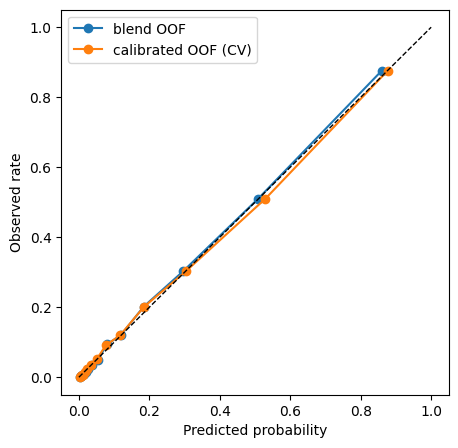

In [16]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(5, 5))
for lbl, p in [("blend OOF", blend_oof), ("calibrated OOF (CV)", cal_oof)]:
    fy, fx = calibration_curve(y, p, n_bins=15, strategy="quantile")
    ax.plot(fx, fy, marker="o", label=lbl)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed rate"); ax.legend()
plt.show()

## 9. Submission

In [17]:
sub = pd.DataFrame({"ID": tst[ID_COL].values, "Target": np.clip(final_tst, 1e-4, 1 - 1e-4)})

# Keep the same row order as the sample submission
sample = pd.read_csv("SampleSubmission.csv")
sub = sample[["ID"]].merge(sub, on="ID", how="left")
assert sub["Target"].notna().all() and len(sub) == len(sample)

print("Mean prediction (train positive rate is 0.15):", sub["Target"].mean().round(4))
sub.to_csv(SUB_PATH, index=False)
print("Saved", SUB_PATH)
sub.head()

Mean prediction (train positive rate is 0.15): 0.1533
Saved submission_cl.csv


,ID,Target
0,ID_ED91AC7A28,0.013753
1,ID_29975A9C7E,0.051345
2,ID_F59CE25650,0.018276
3,ID_E875F68D1A,0.003630
4,ID_2902B1C0D0,0.004414


In [18]:
# Compare with your current best submission (useful sanity check)
prev_path = "submission_LightGBM_new_features_only_extra_Full.csv"
if os.path.exists(prev_path):
    prev = pd.read_csv(prev_path).merge(sub, on="ID", suffixes=("_prev", "_claude"))
    print("Pearson:", prev[["Target_prev", "Target_claude"]].corr().iloc[0, 1].round(4))
    print("Spearman:", prev[["Target_prev", "Target_claude"]].corr("spearman").iloc[0, 1].round(4))

Pearson: 0.9855
Spearman: 0.9823


## 10. Export the model for the Streamlit app

This section saves everything `app/streamlit_app.py` needs to `app/model/stress_model.joblib`:
- all fold models of each family
- the blend weights and the calibration
- the feature list, category levels and group medians
- reference statistics the app uses to explain predictions

The feature pipeline and model class live in **`app/stress_model.py`**, so the app computes exactly the same features. If you change features in section 3, change them there too.

**Models from the cache:** if the predictions came from `claude_cache/`, the fold models are not in memory, so the next cell retrains them with the same folds and seeds. That takes about as long as section 6. Set `EXPORT_SEEDS = [SEEDS[0]]` to export a third of the models and finish faster.

In [19]:
import sys, importlib, joblib
if "app" not in sys.path:
    sys.path.insert(0, "app")
import stress_model as sm
importlib.reload(sm)

assert not USE_CUSTOMER_FEATURES, "The app scores one row at a time, so customer features are not supported."

EXPORT_SEEDS = SEEDS          # e.g. [SEEDS[0]] for a faster, smaller export
fit_fns = {"lgb": lgb_fit_predict, "cat": cat_fit_predict, "xgb": xgb_fit_predict}

for n in names:
    expected = N_FOLDS * len(EXPORT_SEEDS)
    if len(FITTED[n]) == expected:
        print(f"{n}: reusing {expected} fold models from this session")
        continue
    FITTED[n] = []
    print(f"{n}: training {expected} fold models for export...")
    t0 = time.time()
    for seed in EXPORT_SEEDS:
        for tr_idx, va_idx in make_folds(seed):
            fit_fns[n](X.iloc[tr_idx], y[tr_idx], X.iloc[va_idx], y[va_idx], X_test.iloc[:5], seed)
    print(f"   done in {time.time() - t0:.0f}s")

lgb: training 15 fold models for export...
   done in 761s
cat: training 15 fold models for export...
   done in 3156s
xgb: training 15 fold models for export...
   done in 1731s


In [23]:
# Everything the app needs besides the models
group_stats = sm.fit_group_stats(full)
cat_levels = {c: [str(v) for v in full[c].cat.categories] for c in CAT_COLS}

final_oof = cal.predict_proba(z_oof)[:, 1] if CAL_USED else blend_oof
examples = {}
for label, mask in [("Median profile: customers who were NOT stressed", y == 0),
                    ("Median profile: customers who were stressed", y == 1)]:
    part = train.loc[mask, sm.RAW_FEATURES]
    examples[label] = {c: (part[c].mode()[0] if c in CAT_COLS else float(part[c].median()))
                       for c in sm.RAW_FEATURES}

num_feats = [f for f in FEATURES if f not in CAT_COLS]
metadata = dict(
    cv_logloss=float(log_loss(y, cal_oof if CAL_USED else blend_oof)),
    cv_auc=float(roc_auc_score(y, blend_oof)),
    family_metrics={n: dict(logloss=float(log_loss(y, OOF[n])), auc=float(roc_auc_score(y, OOF[n])))
                    for n in names},
    base_rate=float(y.mean()), n_train=int(len(y)), n_folds=N_FOLDS, seeds=list(EXPORT_SEEDS),
    cv_mode=CV_MODE,
    oof_reference=np.sort(final_oof).astype(np.float32),
    feature_medians={"not_stressed": X.loc[y == 0, num_feats].median().to_dict(),
                     "stressed": X.loc[y == 1, num_feats].median().to_dict()},
    examples=examples,
    exported_at=time.strftime("%Y-%m-%d %H:%M"),
)

final_model = sm.StressBlend(
    fitted={n: FITTED[n] for n in names}, names=names, weights=W,
    cal_coef=float(cal.coef_[0, 0]) if CAL_USED else None,
    cal_intercept=float(cal.intercept_[0]) if CAL_USED else None,
    features=FEATURES, cat_levels=cat_levels, group_stats=group_stats, metadata=metadata,
)
print("Unlabelled features:", [f for f in FEATURES if sm.describe(f) == f.replace("_", " ")])

Unlabelled features: []


### Check the app pipeline against the notebook
1. Features rebuilt from **raw** test rows by `stress_model.py` must match `X_test`.
2. Predictions must match `final_tst`. They match almost exactly if the fold models came from this session; retrained models can differ very slightly.

In [24]:
check_raw = test.iloc[:3000]
Xa = final_model.prepare(check_raw)
Xb = X_test.iloc[:3000].reset_index(drop=True)
num = [c for c in FEATURES if c not in CAT_COLS]
feat_diff = np.nanmax(np.abs(Xa[num].to_numpy(float) - Xb[num].to_numpy(float)))
same_nan = (Xa[num].isna().to_numpy() == Xb[num].isna().to_numpy()).all()
print(f"max feature difference: {feat_diff:.2e}   same missing pattern: {same_nan}")
assert feat_diff < 1e-6 and same_nan, "app features differ from the notebook features"

p_app = final_model.predict(check_raw)
pred_diff = np.abs(p_app - final_tst[:3000])
print(f"prediction difference vs final_tst: max={pred_diff.max():.2e}  mean={pred_diff.mean():.2e}")

max feature difference: 3.64e-12   same missing pattern: True
prediction difference vs final_tst: max=8.90e-09  mean=4.86e-10


In [22]:
os.makedirs("app/model", exist_ok=True)
MODEL_FILE = "app/model/stress_model.joblib"
joblib.dump(final_model, MODEL_FILE, compress=3)
print(f"Saved {MODEL_FILE}  ({os.path.getsize(MODEL_FILE) / 1e6:.1f} MB)")

# Reload test, as the app will do it
reloaded = joblib.load(MODEL_FILE)
print("Reloaded OK, sample predictions:", reloaded.predict(test.iloc[:3]).round(4))

Saved app/model/stress_model.joblib  (23.9 MB)
Reloaded OK, sample predictions: [0.0138 0.0513 0.0183]


## 11. Ideas to try next
1. **Customer features, one variant at a time.** For example, `_cmean` only, which describes the person's typical level. Keep a variant only if the OOF log loss drops.
2. **More seeds.** Seed averaging is a cheap win for log loss on a ~0.01 leaderboard gap.
3. **Blend with your old submission.** Average this file's logits with your 0.734 file (e.g. 0.7 / 0.3). Different feature sets often blend well.
4. **Tune with Optuna** on the 5-fold OOF log loss (not on one 70/30 split), one model family at a time.
5. **Do not** oversample, use `class_weight`, or `scale_pos_weight`: they distort the probabilities and cost log loss. If you have used them, calibrate afterwards.